# LLM project: predict peptide retention

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/CompOmics/ML_AI_Analytical_Chemistry_Course/blob/main/05_LLM_Tools/notebooks/TD4_peptide_RT_student.ipynb)

Build your own prediction model with help from an LLM. You choose the features,
model and improvements, and explain how you checked the result. You can ask the
assistant to write the code; you remain responsible for the scientific decisions.

Only the data-loading code is supplied. The rest of this notebook is your project
workspace. Save a copy, write your prompts, and add the code returned by your assistant.

## 1. Meet the data

Peptides are chains of amino acids, written as strings of letters. In reversed-phase
liquid chromatography, their interactions with the column affect when they elute.
More hydrophobic peptides often stay longer, although sequence context and the LC method matter.

We use 6,000 experimentally measured peptides from the DLOmix / ProteomeTools data.
Run the cell below to load the table `data` and preview its first five rows.

| Column | Meaning |
|---|---|
| `sequence` | Peptide amino-acid sequence: the input to your prediction |
| `irt` | Experimentally derived calibrated retention index: the numerical target |

iRT is a reference scale without time units. An iRT of 50 does not mean 50 minutes;
negative values are possible. Larger values correspond to later retention on this scale.
You are building a regression model to predict a number.

In [1]:
import pandas as pd

DATA_URL = (
    "https://raw.githubusercontent.com/wilhelm-lab/dlomix/"
    "f67623048c8692823cff88c3a7521123697af781/example_dataset/proteomTools_train_val.csv"
)
data = pd.read_csv(DATA_URL).sample(n=6000, random_state=42).reset_index(drop=True)
data.head()

,sequence,irt
0,DLPVDSLEGEDFEK,91.048184
1,EMCTVEEPNEEFTSR,48.897757
2,AVSVFFR,82.850771
3,ESFIVLESKPK,59.681840
4,TGAVGDLVIIGDR,95.640349


## 2. Decide what to build

Start by asking your LLM to help you plan the analysis, before asking for code.
You choose how to represent sequences as numbers and which model to try.
Ask for a few understandable options and discuss their advantages and limitations.
There is no required algorithm, feature set or set of parameter values.

You could begin with:

> I want to predict the numerical irt target from peptide sequences in a Colab
> table called data. I am an analytical chemist who does not program.
> Suggest a few simple approaches and explain the choices I need to make.
> Keep the project small enough to run on a CPU with freely available tools.
> Help me plan an honest evaluation. Wait for my choices before writing code.

Adapt this prompt to your own questions. You do not need to upload the full dataset:
give the assistant the column descriptions and a few example rows if useful.

Your plan:

- **Features and the information they describe:** five representations, made more complex one step at a time.
  1. Sum of Kyte-Doolittle hydrophobicity values (1 number). Keeps overall hydrophobicity; loses which residues, order and position.
  2. Counts of the 20 amino acids (20 numbers). Keeps composition (and so length); loses order and position.
  3. Same 20 counts, different model (non-linear).
  4. Counts + counts of the first 2 and last 2 residues + length (61 numbers). Adds information about the peptide ends; still loses order in the middle.
  5. One-hot grid of the full sequence (position x amino acid). Keeps everything in the sequence.
- **Baseline and first model:** a constant (training mean iRT) as the floor, then the hydrophobicity sum with a straight line
  (slope and intercept learned from training). Next: Ridge regression on counts, gradient boosting on counts,
  gradient boosting on counts + terminal counts, and a small 1D convolutional network (Keras) on the one-hot grid.
- **How you will split the data and compare results:**
  - Repeated sequences are merged (mean iRT) so each peptide appears once.
  - Peptides where one sequence is found inside another (e.g. a missed cleavage) form a *family*; a whole family goes into one group.
  - Families are shuffled with random seed 42 and split 70 / 15 / 15 into training, validation and test peptides. The split is saved to a file.
  - Everything that is learned (scaling values, model parameters, the baseline constant) comes from training peptides only.
  - Errors: MAE (main measure, used to choose), R² and Δ95. Choice made on validation MAE only. The test group is used once, at the end.
  - Edit distance to the nearest training peptide shows which peptides are well or poorly represented in training.

## 3. Build your model with the LLM

Ask for code in small pieces that you can run and discuss. Use the table `data`
already loaded above. You can add code cells when needed; you do not have to
write the Python yourself.

Your analysis should:

- Check missing values and repeated sequences before modelling.
- Keep separate training, validation and test peptides. Identical sequences must
  stay in one group. Use the same split when comparing approaches and record the random seed.
- Turn sequences into features using the representation you chose.
- Fit a simple baseline that ignores sequence, then a model of your choice.
- Learn feature-preparation settings and model parameters from training peptides only.

A baseline could predict the same value for every peptide. Ask the assistant why
that comparison is useful and decide which constant to use.

Check one small example yourself. For instance, if your features count amino acids,
work out a short sequence by hand and compare it with the code's output.
Ask the assistant to explain which code learns from the targets and which data it uses.
If something fails, include the error in a follow-up prompt and check the proposed repair.

### 3.1 Settings and tools

All choices that must stay fixed are written once here, so every approach uses the same values.

In [2]:
%pip install -q rapidfuzz

# Settings used everywhere in this notebook
SEED = 42                      # random seed for the split and the models
TRAIN_FRACTION = 0.70          # training peptides
VALIDATION_FRACTION = 0.15     # validation peptides; the test group gets the remaining 0.15
AMINO_ACIDS = "ACDEFGHIKLMNPQRSTVWY"

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx
from rapidfuzz.distance import Levenshtein
from rapidfuzz.process import cdist
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, r2_score

# One fixed colour per group and per approach, used in every plot
GROUP_COLORS = {"train": "#2a78d6", "validation": "#eb6834", "test": "#1baf7a"}
APPROACH_COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"]

def approach_color(name):
    return APPROACH_COLORS[int(name.split(".")[0])]   # "2. AA counts + Ridge" -> colour 2

plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False,
                     "axes.edgecolor": "#c3c2b7", "axes.grid": True, "axes.axisbelow": True,
                     "grid.color": "#e1e0d9", "grid.linewidth": 0.6,
                     "lines.linewidth": 2, "figure.dpi": 110})

Note: you may need to restart the kernel to use updated packages.


**What this cell does:** installs `rapidfuzz` (a free package for edit distance) and loads the tools used later. It also fixes the seed, the split fractions, the order of the 20 amino acids, and one colour per group and per approach, so the same approach has the same colour in every plot.

**Peptides used:** none.

**Your check:** `len(AMINO_ACIDS)` should give 20, and `sorted(AMINO_ACIDS) == list(AMINO_ACIDS)` should give `True` (the letters are in alphabetical order).

### 3.2 Inspect the table before modelling

Missing values, unexpected letters, repeated sequences and peptide lengths.
Nothing is learned here.

In [3]:
print("Rows, columns:", data.shape)

# Missing values in the two columns we use
print("\nMissing values per column:")
print(data[["sequence", "irt"]].isna().sum())

# Which letters appear in the sequences?
all_letters = sorted(set("".join(data["sequence"])))
print("\nLetters found:", all_letters)
print("Non-standard letters:", [x for x in all_letters if x not in AMINO_ACIDS])

# Repeated sequences
counts = data["sequence"].value_counts()
repeated = counts[counts > 1]
print("\nUnique sequences:", data["sequence"].nunique())
print("Sequences appearing more than once:", len(repeated))

# For repeated sequences: how far apart are their iRT values?
if len(repeated) > 0:
    rep_rows = data[data["sequence"].isin(repeated.index)]
    spread = rep_rows.groupby("sequence")["irt"].agg(["count", "min", "max"])
    spread["range"] = spread["max"] - spread["min"]
    print("\nLargest iRT disagreement between copies:")
    print(spread.sort_values("range", ascending=False).head(10))

# Peptide length and enzyme check (no iRT used here)
lengths = data["sequence"].str.len()
print("\nPeptide length summary:")
print(lengths.describe())
print("Fraction ending in K or R (tryptic):",
      round(data["sequence"].str[-1].isin(["K", "R"]).mean(), 3))

Rows, columns: (6000, 2)

Missing values per column:
sequence    0
irt         0
dtype: int64

Letters found: ['A', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'K', 'L', 'M', 'N', 'P', 'Q', 'R', 'S', 'T', 'V', 'W', 'Y']
Non-standard letters: []

Unique sequences: 6000
Sequences appearing more than once: 0

Peptide length summary:
count    6000.000000
mean       13.631167
std         5.034417
min         7.000000
25%        10.000000
50%        13.000000
75%        16.000000
max        40.000000
Name: sequence, dtype: float64
Fraction ending in K or R (tryptic): 1.0


**What this cell does:** counts missing values, lists every letter used, finds sequences that appear more than once (and how much their iRT values disagree), and summarises peptide length.

**Peptides used:** all 6,000 rows; there are no groups yet. Only the iRT values of repeated sequences are looked at, as a data-quality check.

**Your check:** run `data["sequence"].iloc[0]`, count its letters by hand and compare with `lengths.iloc[0]`.

### 3.3 Merge repeated sequences

Each sequence should appear once. If a sequence was measured more than once, we keep its mean iRT.

In [4]:
peptides = data.groupby("sequence", as_index=False)["irt"].mean()

print("Rows before:", len(data))
print("Unique peptides after:", len(peptides))

Rows before: 6000
Unique peptides after: 6000


**What this cell does:** makes the table `peptides` with one row per unique sequence; repeated sequences get the mean of their iRT values.

**Peptides used:** all peptides (no groups yet). Taking a mean per sequence uses no information from other peptides, so it is not learning anything.

**Your check:** the number after merging must equal `data["sequence"].nunique()` from cell 3.2. If cell 3.2 listed a repeated sequence, run `data[data["sequence"] == "PASTE_HERE"]`, average its iRT values by hand and compare with `peptides[peptides["sequence"] == "PASTE_HERE"]`.

### 3.4 Find related peptides (one sequence inside another)

A peptide such as `ELVISK` can be found inside a longer peptide such as `ELVISKAAR` (a missed cleavage).
Such peptides are linked. All peptides that are linked, directly or through other peptides, form one *family*.
A family will go into one group, so the model is never tested on a peptide whose sub- or super-sequence it was trained on.
This cell takes up to about a minute.

In [5]:
sequences = peptides["sequence"].tolist()

# Every pair (short, long) where the short sequence is found inside the long one
pairs = []
for i, short in enumerate(sequences):
    for j, long in enumerate(sequences):
        if len(short) < len(long) and short in long:
            pairs.append((i, j))
print("Pairs where one peptide is inside another:", len(pairs))
for i, j in pairs[:5]:
    print("  ", sequences[i], "is inside", sequences[j])

# Peptides linked directly or through other peptides form one family
graph = nx.Graph()
graph.add_nodes_from(range(len(sequences)))
graph.add_edges_from(pairs)
family = [0] * len(sequences)
for family_id, members in enumerate(nx.connected_components(graph)):
    for i in members:
        family[i] = family_id
peptides["family"] = family

family_sizes = peptides["family"].value_counts()
print("\nNumber of families:", len(family_sizes))
print("Families with more than one peptide:", (family_sizes > 1).sum())
print("Largest family size:", family_sizes.max())
print(peptides[peptides["family"] == family_sizes.index[0]]["sequence"].tolist())

Pairs where one peptide is inside another: 23
   ADDMSDDQGTSVQSK is inside GKADDMSDDQGTSVQSK
   DLGLAADLPGGAEGAAAQPQAVLR is inside DLGLAADLPGGAEGAAAQPQAVLRQPELR
   EEGYDSVFSVVR is inside IREEGYDSVFSVVR
   EITEGDEVEVYSR is inside LPPPADYNKEITEGDEVEVYSR
   EPGEDCPSPQPAPASPR is inside EDKEPGEDCPSPQPAPASPR

Number of families: 5977
Families with more than one peptide: 23
Largest family size: 2
['EEGYDSVFSVVR', 'IREEGYDSVFSVVR']


**What this cell does:** compares every sequence with every other sequence, links the pairs where one is found inside the other, and gives each peptide a family number. Unrelated peptides form a family of size 1.

**Peptides used:** all unique peptides, sequences only (iRT is not used).

**Your check:** take one printed pair, for example the first line, and confirm by eye that the short sequence appears letter for letter inside the long one.

### 3.5 Split families into training, validation and test groups

Families are shuffled with the seed and handed out in order: training until 70% of peptides, validation until 85%, the rest is test.
The split is saved to `split_seed42.csv`, so it can be reloaded and every approach uses the same groups.

In [6]:
rng = np.random.default_rng(SEED)
family_ids = peptides["family"].unique()
rng.shuffle(family_ids)

group_of_family = {}
running_total = 0
for f in family_ids:
    if running_total < TRAIN_FRACTION * len(peptides):
        group_of_family[f] = "train"
    elif running_total < (TRAIN_FRACTION + VALIDATION_FRACTION) * len(peptides):
        group_of_family[f] = "validation"
    else:
        group_of_family[f] = "test"
    running_total += family_sizes[f]

peptides["group"] = peptides["family"].map(group_of_family)
peptides.to_csv(f"split_seed{SEED}.csv", index=False)

train = peptides[peptides["group"] == "train"].reset_index(drop=True)
val = peptides[peptides["group"] == "validation"].reset_index(drop=True)
test = peptides[peptides["group"] == "test"].reset_index(drop=True)
print("Training:", len(train), " Validation:", len(val), " Test:", len(test))

Training: 4200  Validation: 900  Test: 900


**What this cell does:** assigns each family to one group, saves the split, and makes three tables: `train`, `val` and `test`.

**Peptides used:** all unique peptides, by family; iRT is not used to decide the groups.

**Your check:** the three numbers printed must add up to the number of unique peptides from cell 3.3, and be close to 70 / 15 / 15 percent.

### 3.6 Confirm the groups are separate

From here on, only training iRT values are summarised.

Sequences shared by training and validation: 0
Sequences shared by training and test: 0
Sequences shared by validation and test: 0
Families found in more than one group: 0
Validation peptides related to a training peptide: 0
Test peptides related to a training peptide: 0

Training iRT summary:
count    4200.000000
mean       62.700967
std        45.159210
min       -37.397545
25%        28.386377
50%        61.550288
75%        96.722516
max       168.875446
Name: irt, dtype: float64


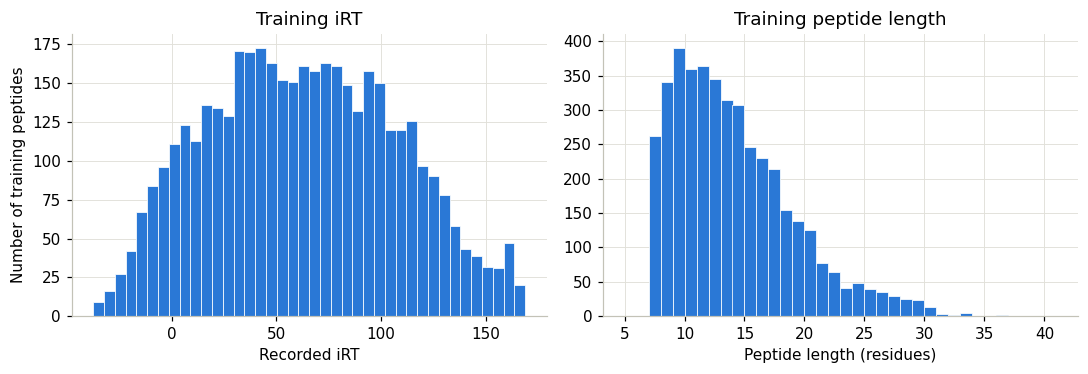

In [7]:
train_set, val_set, test_set = set(train["sequence"]), set(val["sequence"]), set(test["sequence"])
print("Sequences shared by training and validation:", len(train_set & val_set))
print("Sequences shared by training and test:", len(train_set & test_set))
print("Sequences shared by validation and test:", len(val_set & test_set))

families_per_group = peptides.groupby("family")["group"].nunique()
print("Families found in more than one group:", (families_per_group > 1).sum())

# Direct check: no validation or test peptide is inside a training peptide, or the other way round
def related_to_training(sequence):
    return any(sequence in t or t in sequence for t in train_set)

print("Validation peptides related to a training peptide:", val["sequence"].apply(related_to_training).sum())
print("Test peptides related to a training peptide:", test["sequence"].apply(related_to_training).sum())

print("\nTraining iRT summary:")
print(train["irt"].describe())

fig, (ax_irt, ax_len) = plt.subplots(1, 2, figsize=(10, 3.5))
ax_irt.hist(train["irt"], bins=40, color=GROUP_COLORS["train"], edgecolor="white", linewidth=0.5)
ax_irt.set_xlabel("Recorded iRT")
ax_irt.set_ylabel("Number of training peptides")
ax_irt.set_title("Training iRT")
ax_len.hist(train["sequence"].str.len(), bins=range(5, 42), color=GROUP_COLORS["train"], edgecolor="white", linewidth=0.5)
ax_len.set_xlabel("Peptide length (residues)")
ax_len.set_title("Training peptide length")
plt.tight_layout()
plt.show()

**What this cell does:** checks that no sequence and no family appears in two groups, and re-checks directly that no validation or test peptide is inside (or contains) a training peptide. All printed counts should be 0. Then it summarises training iRT and draws histograms of training iRT and training peptide length. Validation and test iRT are not plotted, so you cannot be influenced by them.

**Peptides used:** all three groups' sequences; iRT and lengths of training peptides only.

**Your check:** pick a family with more than one peptide, e.g. `f = family_sizes.index[0]`, run `peptides[peptides["family"] == f]` and confirm by eye that the `group` column has one value.

### 3.7 How well is each peptide represented in training?

The **edit distance** (Levenshtein) between two sequences is the smallest number of single-letter changes, insertions or deletions
that turns one into the other. We divide it by the length of the longer sequence: 0 means identical, 1 means nothing in common.
For every peptide we find its *nearest training peptide*:

- small distance: a near-copy is in training (well represented, maybe too well),
- large distance: an outlier, unlike anything the model learned from.

Training peptides are compared with the other training peptides (not with themselves). The edges of the three bins
(close / typical / far) are the thirds of the training distances, so they are also learned from training only.

          train  validation     test
count  4200.000     900.000  900.000
mean      0.492       0.497    0.497
std       0.083       0.078    0.078
min       0.040       0.133    0.133
25%       0.444       0.455    0.455
50%       0.500       0.500    0.500
75%       0.550       0.550    0.556
max       0.667       0.667    0.667

Bin edges (from training): [0.462 0.533]

Most isolated training peptides (outliers):
                               sequence  nearest_train_dist
565         DRYEEYKEVEEHPPLSSSPVEHEGVLK            0.666667
1205     GHAPVEQQHITHKEPLVANDILNHPNFVKK            0.666667
2019              LFSQQGYFLQMHPDGTIDGTK            0.666667
2341        LRPHFLSVCNPDFSQINCSEGYIQNYR            0.666667
2419  LTTPADKALIAPDHVVPAPEECYVYSPLGSAYK            0.666667

Training peptides with the closest neighbour (near-copies):
                       sequence  nearest_train_dist
1801   KHPGGGESDASPEAGSGGGGVALK            0.040000
1802  KHPGGGESDASPEAGSGGGGVALKK            0.040000
186

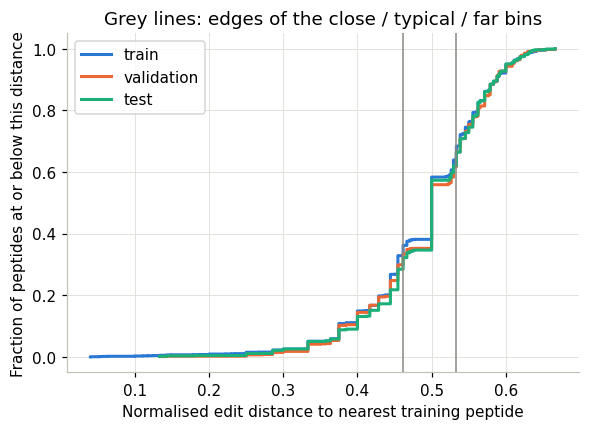

In [8]:
train_sequences = train["sequence"].tolist()

def nearest_training_distance(sequences, is_training=False):
    distances = cdist(sequences, train_sequences, scorer=Levenshtein.normalized_distance,
                      dtype=np.float32, workers=-1)
    if is_training:
        np.fill_diagonal(distances, np.inf)   # do not compare a peptide with itself
    return distances.min(axis=1)

train["nearest_train_dist"] = nearest_training_distance(train_sequences, is_training=True)
val["nearest_train_dist"] = nearest_training_distance(val["sequence"].tolist())
test["nearest_train_dist"] = nearest_training_distance(test["sequence"].tolist())

# Bin edges from training peptides only
bin_edges = [-np.inf, *train["nearest_train_dist"].quantile([1 / 3, 2 / 3]), np.inf]
for table in (train, val, test):
    table["similarity"] = pd.cut(table["nearest_train_dist"], bin_edges, labels=["close", "typical", "far"])

summary = pd.DataFrame({name: table["nearest_train_dist"].describe()
                        for name, table in [("train", train), ("validation", val), ("test", test)]})
print(summary.round(3))
print("\nBin edges (from training):", np.round(bin_edges[1:3], 3))

print("\nMost isolated training peptides (outliers):")
print(train.nlargest(5, "nearest_train_dist")[["sequence", "nearest_train_dist"]])
print("\nTraining peptides with the closest neighbour (near-copies):")
print(train.nsmallest(5, "nearest_train_dist")[["sequence", "nearest_train_dist"]])

# Length outside the training range means the model must extrapolate
train_lengths = train["sequence"].str.len()
for name, table in [("validation", val), ("test", test)]:
    outside = ~table["sequence"].str.len().between(train_lengths.min(), train_lengths.max())
    print(f"{name} peptides with a length outside the training range:", outside.sum())

# Rare residues are learned from few examples
residue_counts = pd.Series({aa: train["sequence"].str.count(aa).sum() for aa in AMINO_ACIDS})
print("\nAmino-acid occurrences in training (rarest first):")
print(residue_counts.sort_values().head(6))

plt.figure(figsize=(6, 4))
for name, table in [("train", train), ("validation", val), ("test", test)]:
    distances = np.sort(table["nearest_train_dist"])
    fraction = np.arange(1, len(distances) + 1) / len(distances)
    plt.step(distances, fraction, where="post", color=GROUP_COLORS[name], label=name)
for edge in bin_edges[1:3]:
    plt.axvline(edge, color="#898781", linewidth=1)
plt.xlabel("Normalised edit distance to nearest training peptide")
plt.ylabel("Fraction of peptides at or below this distance")
plt.title("Grey lines: edges of the close / typical / far bins")
plt.legend()
plt.show()

**What this cell does:** computes, for every peptide, the normalised edit distance to its nearest training peptide, puts each peptide in a close / typical / far bin, lists outliers and near-copies in training, checks length range and rare amino acids, and draws the distances per group as cumulative curves (a curve that rises early means many peptides with a close training neighbour). Cumulative curves are used because the distances are fractions such as 1/2 or 7/13, which make a histogram spiky. If the three curves lie on top of each other, validation and test peptides are about as well represented as training peptides are among themselves.

**Peptides used:** sequences of all three groups, compared with training sequences only. No iRT is used.

**Your check:** `PEPTIDEK` and `PEPTIDER` differ by one letter out of 8, so the normalised distance is 1/8 = 0.125. Run `Levenshtein.normalized_distance("PEPTIDEK", "PEPTIDER")` and compare. Then try `"PEPTIDEK"` vs `"PEPTIDE"` (one deletion, longer length 8).

### 3.8 Error measures and a results table

- **MAE**: mean of the absolute errors, in iRT units. Lower is better. Used to choose.
- **R²**: fraction of the iRT spread explained by the model. 1 is perfect, 0 is no better than predicting that group's mean.
- **Δ95**: width of the window around the prediction that holds 95% of peptides, i.e. 2 × the 95th percentile of the
  absolute error. Some papers report half of this width; we use the full width.

`add_result` predicts training and validation peptides with an approach, adds a row to the results table, and stores the
approach so it can be used on the test group at the end. It never touches the test group.

In [9]:
def evaluate(recorded, predicted):
    errors = np.abs(np.asarray(recorded) - np.asarray(predicted))
    return {"MAE": errors.mean(),
            "R2": r2_score(recorded, predicted),
            "Delta95": 2 * np.percentile(errors, 95)}

results = []          # one row per approach
predictors = {}       # approach name -> function that predicts iRT from sequences
val_predictions = {}  # approach name -> validation predictions

def add_result(name, change, predict_fn):
    row = {"Approach": name, "What changed": change}
    for group_name, table in [("Train", train), ("Val", val)]:
        scores = evaluate(table["irt"], predict_fn(table["sequence"]))
        for key, value in scores.items():
            row[f"{group_name} {key}"] = round(value, 2)
    results.append(row)
    predictors[name] = predict_fn
    val_predictions[name] = predict_fn(val["sequence"])
    return pd.DataFrame([row])

**What this cell does:** defines how errors are calculated and a helper that records training and validation errors for each approach.

**Peptides used:** none yet; later it uses training and validation peptides only.

**Your check:** for recorded iRT 10, 20, 30, 40 and predictions 12, 18, 30, 50 the errors are 2, 2, 0 and 10, so the MAE is 14/4 = 3.5. Run `evaluate([10, 20, 30, 40], [12, 18, 30, 50])` and compare the MAE.

### 3.9 Reference: the same value for every peptide

Predicting the training mean for every peptide ignores the sequence completely. Any model that uses the sequence should beat it.
The constant is learned from training peptides only.

In [10]:
train_mean = train["irt"].mean()
print("Training mean iRT:", round(train_mean, 2))

def predict_mean(sequences):
    return np.full(len(sequences), train_mean)

add_result("0. Training mean", "Same value for every peptide", predict_mean)

Training mean iRT: 62.7


,Approach,What changed,Train MAE,Train R2,Train Delta95,Val MAE,Val R2,Val Delta95
0,0. Training mean,Same value for every peptide,37.69,0.0,165.52,39.2,-0.0,172.14


**What this cell does:** computes the mean training iRT and uses it as the prediction for every peptide.

**Peptides used:** training iRT for the constant; training and validation peptides for the errors.

**Your check:** the training R² must be exactly 0.00, because R² compares with the mean of that same group. Explain why the validation R² is close to 0 (it can be slightly below).

### 3.10 Approach 1 (baseline): Kyte-Doolittle sum + straight line

Each peptide becomes one number: the sum of the Kyte-Doolittle hydropathy values of its amino acids.
A straight line `irt = a × sum + b` is fitted. Learned: `a` and `b`. Fixed setting: the scale itself (published, not learned).

In [11]:
KYTE_DOOLITTLE = {"A": 1.8, "R": -4.5, "N": -3.5, "D": -3.5, "C": 2.5,
                  "Q": -3.5, "E": -3.5, "G": -0.4, "H": -3.2, "I": 4.5,
                  "L": 3.8, "K": -3.9, "M": 1.9, "F": 2.8, "P": -1.6,
                  "S": -0.8, "T": -0.7, "W": -0.9, "Y": -1.3, "V": 4.2}

def kd_sum(sequence):
    return sum(KYTE_DOOLITTLE[aa] for aa in sequence)

def kd_table(sequences):
    return pd.DataFrame({"kd_sum": [kd_sum(s) for s in sequences]})

model_kd = LinearRegression().fit(kd_table(train["sequence"]), train["irt"])
print("Learned slope a:", round(model_kd.coef_[0], 3), " intercept b:", round(model_kd.intercept_, 3))

def predict_kd(sequences):
    return model_kd.predict(kd_table(sequences))

add_result("1. KD sum + line", "Hydrophobicity sum, straight line", predict_kd)

Learned slope a: 2.113  intercept b: 73.642


,Approach,What changed,Train MAE,Train R2,Train Delta95,Val MAE,Val R2,Val Delta95
0,1. KD sum + line,"Hydrophobicity sum, straight line",32.65,0.24,141.68,33.81,0.24,149.46


**What this cell does:** turns each sequence into its hydrophobicity sum and fits a straight line on training peptides.

**Peptides used:** training peptides to learn `a` and `b`; training and validation peptides for the errors.

**Your check:** `GAVK` = −0.4 + 1.8 + 4.2 − 3.9 = 1.7. Run `kd_sum("GAVK")` and compare (a tiny rounding difference such as 1.7000000000000002 is normal).

### 3.11 Approach 2: amino-acid counts + Ridge regression (feature change)

Each peptide becomes 20 numbers: how often each amino acid occurs. Ridge regression learns one coefficient per amino acid
plus an intercept: in effect, a retention scale learned from this LC data. Counts are first scaled with the training mean and
standard deviation. Chosen setting: Ridge strength `alpha`, picked on validation MAE.

alpha = 0.01   validation MAE = 12.24
alpha = 0.1    validation MAE = 12.24
alpha = 1      validation MAE = 12.24
alpha = 10     validation MAE = 12.25
alpha = 100    validation MAE = 12.39
Chosen alpha: 0.01

Learned iRT change per residue (training peptides):
H   -19.43
K   -19.42
R   -18.33
N    -3.28
Q    -2.35
C    -1.73
G    -1.72
S    -0.75
T     1.46
D     1.90
E     1.95
P     2.96
A     3.60
M     8.75
Y    12.61
V    13.40
I    23.58
L    26.62
F    31.91
W    34.65


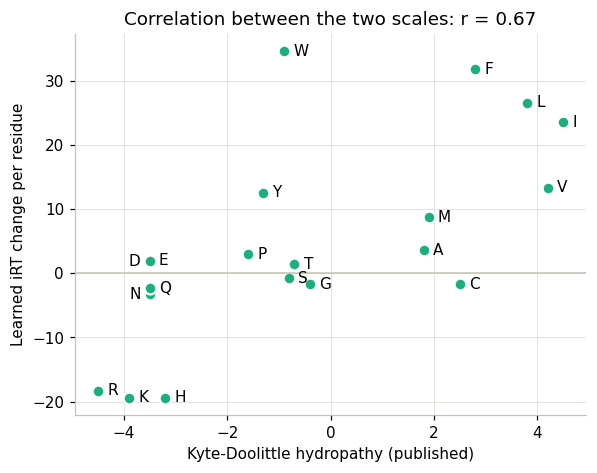

,Approach,What changed,Train MAE,Train R2,Train Delta95,Val MAE,Val R2,Val Delta95
0,2. AA counts + Ridge,20 counts instead of 1 sum,12.53,0.87,63.83,12.24,0.89,58.74


In [12]:
def aa_counts(sequence):
    return [sequence.count(aa) for aa in AMINO_ACIDS]

def count_table(sequences):
    return pd.DataFrame([aa_counts(s) for s in sequences], columns=list(AMINO_ACIDS))

X_train_counts = count_table(train["sequence"])
X_val_counts = count_table(val["sequence"])

best_mae = np.inf
for alpha in [0.01, 0.1, 1, 10, 100]:
    model = make_pipeline(StandardScaler(), Ridge(alpha=alpha)).fit(X_train_counts, train["irt"])
    val_mae = mean_absolute_error(val["irt"], model.predict(X_val_counts))
    print(f"alpha = {alpha:<6} validation MAE = {val_mae:.2f}")
    if val_mae < best_mae:
        best_mae, best_alpha, model_ridge = val_mae, alpha, model
print("Chosen alpha:", best_alpha)

# Learned retention coefficient per amino acid, in iRT units per residue
scaler, ridge = model_ridge.named_steps["standardscaler"], model_ridge.named_steps["ridge"]
coefficients = pd.Series(ridge.coef_ / scaler.scale_, index=list(AMINO_ACIDS)).sort_values()
print("\nLearned iRT change per residue (training peptides):")
print(coefficients.round(2).to_string())

# Published hydropathy (x) against what the LC data taught the model (y)
kd_values = [KYTE_DOOLITTLE[aa] for aa in coefficients.index]
plt.figure(figsize=(6, 4.5))
plt.scatter(kd_values, coefficients, s=60, color=APPROACH_COLORS[2], edgecolor="white", linewidth=1.5)
for aa, x, y in zip(coefficients.index, kd_values, coefficients):
    left = aa in "DN"   # D/E and N/Q share a Kyte-Doolittle value: put one label left, one right
    plt.annotate(aa, (x, y), xytext=(-6 if left else 6, 0), textcoords="offset points",
                 ha="right" if left else "left", va="center", fontsize=10)
plt.axhline(0, color="#c3c2b7", linewidth=1)
plt.xlabel("Kyte-Doolittle hydropathy (published)")
plt.ylabel("Learned iRT change per residue")
plt.title(f"Correlation between the two scales: r = {np.corrcoef(kd_values, coefficients)[0, 1]:.2f}")
plt.show()

def predict_ridge(sequences):
    return model_ridge.predict(count_table(sequences))

add_result("2. AA counts + Ridge", "20 counts instead of 1 sum", predict_ridge)

**What this cell does:** counts amino acids, fits Ridge regression for five values of `alpha` on training peptides, keeps the `alpha` with the lowest validation MAE, and prints the learned iRT change per residue. The plot puts each amino acid at its Kyte-Doolittle value (x) and its learned value (y): letters far from the general trend are residues where the published scale and this LC data disagree.

**Peptides used:** training peptides for scaling values and coefficients; validation peptides to choose `alpha`.

**Your check:** `PEPTIDEK` contains P 2, E 2, T 1, I 1, D 1, K 1 and zero of the rest. Run `count_table(["PEPTIDEK"])` and compare.

## 4. Compare and improve before opening the test results

Use the validation peptides to compare your model with the baseline.
Choose an error measure and explain it in words. Mean absolute error (MAE) is one
useful option: for a target of 50 and a prediction of 42, the absolute error is 8 iRT units.
MAE averages these distances, so lower is better. It is not classification accuracy.

Try one deliberate change, such as a different representation, model or setting.
Ask the assistant to explain why it might help, then check whether it actually does.
Keep the baseline and previous result for comparison. You can also keep the baseline
as your final choice if the models do not improve on it.

Record your comparison before looking at test results (copy the MAE values from the table printed in 4.4):

| Approach | What changed? | Training error (MAE) | Validation error (MAE) |
|---|---|---|---|
| 0. Training mean | Same value for every peptide | | |
| 1. KD sum + line (baseline) | Hydrophobicity sum, straight line | | |
| 2. AA counts + Ridge | 20 counts instead of 1 sum | | |
| 3. AA counts + boosting | Non-linear model, same features as 2 | | |
| 4. Counts + termini + boosting | First/last 2 residues and length added | | |
| 5. One-hot + CNN | Full sequence, neural network | | |

Write which approach you choose and why. A more complicated model need not be better.

### 4.1 Approach 3: same counts + gradient boosting (model change)

Same 20 counts as approach 2; only the model changes. Gradient boosting adds up many small decision trees, so it can learn
non-linear effects and interactions (for example, one residue mattering more in short peptides). Learned: the split points and
leaf values of every tree. Chosen settings: learning rate, tree size and number of trees, picked on validation MAE.
The same search is reused for approach 4.

In [13]:
def tune_boosting(X_train, X_val):
    best_mae = np.inf
    for learning_rate in [0.05, 0.1]:
        for max_leaf_nodes in [15, 31]:
            for max_iter in [200, 500]:
                model = HistGradientBoostingRegressor(learning_rate=learning_rate, max_leaf_nodes=max_leaf_nodes,
                                                      max_iter=max_iter, early_stopping=False, random_state=SEED)
                model.fit(X_train, train["irt"])
                val_mae = mean_absolute_error(val["irt"], model.predict(X_val))
                print(f"learning_rate={learning_rate}, max_leaf_nodes={max_leaf_nodes}, "
                      f"max_iter={max_iter}: validation MAE = {val_mae:.2f}")
                if val_mae < best_mae:
                    best_mae, best_model = val_mae, model
    print("Chosen settings:", {k: best_model.get_params()[k] for k in ["learning_rate", "max_leaf_nodes", "max_iter"]})
    return best_model

model_gb_counts = tune_boosting(X_train_counts, X_val_counts)

def predict_gb_counts(sequences):
    return model_gb_counts.predict(count_table(sequences))

add_result("3. AA counts + boosting", "Non-linear model, same features as 2", predict_gb_counts)

c:\Users\robbi\anaconda3\envs\deeplc_mt\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "c:\Users\robbi\anaconda3\envs\deeplc_mt\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "c:\Users\robbi\anaconda3\envs\deeplc_mt\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\robbi\anaconda3\envs\deeplc_mt\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "c:\Users\robbi\anaconda3\envs\deeplc_mt\Lib\subprocess

learning_rate=0.05, max_leaf_nodes=15, max_iter=200: validation MAE = 12.14
learning_rate=0.05, max_leaf_nodes=15, max_iter=500: validation MAE = 11.41
learning_rate=0.05, max_leaf_nodes=31, max_iter=200: validation MAE = 12.05
learning_rate=0.05, max_leaf_nodes=31, max_iter=500: validation MAE = 11.88
learning_rate=0.1, max_leaf_nodes=15, max_iter=200: validation MAE = 11.41
learning_rate=0.1, max_leaf_nodes=15, max_iter=500: validation MAE = 11.50
learning_rate=0.1, max_leaf_nodes=31, max_iter=200: validation MAE = 11.98
learning_rate=0.1, max_leaf_nodes=31, max_iter=500: validation MAE = 12.25
Chosen settings: {'learning_rate': 0.05, 'max_leaf_nodes': 15, 'max_iter': 500}


,Approach,What changed,Train MAE,Train R2,Train Delta95,Val MAE,Val R2,Val Delta95
0,3. AA counts + boosting,"Non-linear model, same features as 2",8.83,0.93,45.54,11.41,0.9,58.33


**What this cell does:** tries 8 combinations of settings, each trained on training peptides, and keeps the one with the lowest validation MAE. Watch the gap between training and validation MAE in the table: a large gap means overfitting.

**Peptides used:** training peptides to build the trees; validation peptides to choose the settings.

**Your check:** compute the validation MAE yourself with `np.mean(np.abs(val["irt"] - predict_gb_counts(val["sequence"])))` and compare with `Val MAE` in the table.

### 4.2 Approach 4: counts + peptide ends + length, gradient boosting (feature change)

Same model search as approach 3; only the features change. Added: counts of the first 2 residues (N-terminus), counts of the
last 2 residues (C-terminus) and the length. 61 numbers per peptide. Order in the middle of the peptide is still lost.

In [14]:
def terminal_features(sequence):
    first_two, last_two = sequence[:2], sequence[-2:]
    return (aa_counts(sequence)
            + [first_two.count(aa) for aa in AMINO_ACIDS]
            + [last_two.count(aa) for aa in AMINO_ACIDS]
            + [len(sequence)])

terminal_columns = (list(AMINO_ACIDS) + ["N_" + aa for aa in AMINO_ACIDS]
                    + ["C_" + aa for aa in AMINO_ACIDS] + ["length"])

def terminal_table(sequences):
    return pd.DataFrame([terminal_features(s) for s in sequences], columns=terminal_columns)

model_gb_terminal = tune_boosting(terminal_table(train["sequence"]), terminal_table(val["sequence"]))

def predict_gb_terminal(sequences):
    return model_gb_terminal.predict(terminal_table(sequences))

add_result("4. Counts + termini + boosting", "First/last 2 residues and length added", predict_gb_terminal)

learning_rate=0.05, max_leaf_nodes=15, max_iter=200: validation MAE = 11.39
learning_rate=0.05, max_leaf_nodes=15, max_iter=500: validation MAE = 10.10
learning_rate=0.05, max_leaf_nodes=31, max_iter=200: validation MAE = 10.82
learning_rate=0.05, max_leaf_nodes=31, max_iter=500: validation MAE = 10.20
learning_rate=0.1, max_leaf_nodes=15, max_iter=200: validation MAE = 10.28
learning_rate=0.1, max_leaf_nodes=15, max_iter=500: validation MAE = 9.90
learning_rate=0.1, max_leaf_nodes=31, max_iter=200: validation MAE = 10.34
learning_rate=0.1, max_leaf_nodes=31, max_iter=500: validation MAE = 10.44
Chosen settings: {'learning_rate': 0.1, 'max_leaf_nodes': 15, 'max_iter': 500}


,Approach,What changed,Train MAE,Train R2,Train Delta95,Val MAE,Val R2,Val Delta95
0,4. Counts + termini + boosting,First/last 2 residues and length added,5.77,0.97,30.04,9.9,0.92,54.11


**What this cell does:** builds the 61 features and repeats the same settings search as approach 3.

**Peptides used:** training peptides to build the trees; validation peptides to choose the settings.

**Your check:** for `PEPTIDEK`: N-terminal counts P 1 and E 1, C-terminal counts E 1 and K 1, length 8. Run `terminal_table(["PEPTIDEK"]).loc[0, lambda r: r > 0]` to see only the non-zero features and compare.

### 4.3 Approach 5: one-hot sequence + small 1D CNN (Keras)

Each peptide becomes a grid: one row per position, one column per amino acid, with a 1 where that amino acid sits.
Short peptides are filled up with rows of zeros to the longest *training* length. A convolutional network slides small filters
along the sequence to detect local patterns. Learned: all filter and layer weights (tens of thousands of numbers).
Chosen settings: number of filters and filter width (picked on validation MAE), plus fixed choices (layers, dropout 0.2,
learning rate 0.001, batch size 64). iRT is scaled with the training mean and standard deviation during training.

**Note:** training stops when the validation error has not improved for 15 epochs (early stopping). That makes the number of
epochs a setting chosen on validation, so this approach's validation error is slightly optimistic. Runs a few minutes on CPU.

Grid length (longest training peptide): 36
Validation peptides longer than that (cut off): 0
Test peptides longer than that (cut off): 2
filters=32, kernel_size=3: epochs run = 33, validation MAE = 8.29
filters=32, kernel_size=5: epochs run = 35, validation MAE = 8.26
filters=64, kernel_size=3: epochs run = 35, validation MAE = 8.23
filters=64, kernel_size=5: epochs run = 21, validation MAE = 8.30
Chosen (filters, kernel_size): (64, 3)


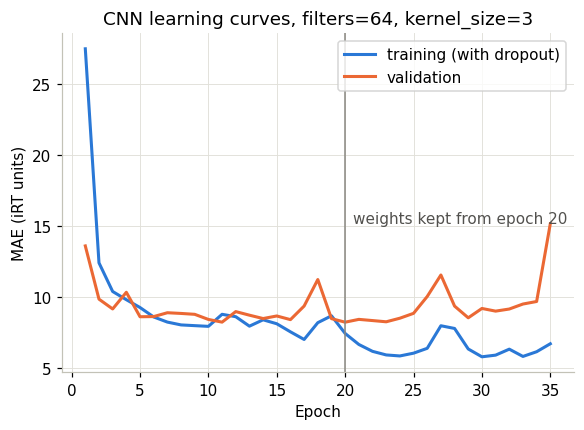

,Approach,What changed,Train MAE,Train R2,Train Delta95,Val MAE,Val R2,Val Delta95
0,5. One-hot + CNN,"Full sequence, neural network",4.79,0.97,25.88,8.23,0.94,42.69


In [15]:
import tensorflow as tf
from tensorflow import keras

MAX_LENGTH = train["sequence"].str.len().max()   # from training peptides only
print("Grid length (longest training peptide):", MAX_LENGTH)
print("Validation peptides longer than that (cut off):", (val["sequence"].str.len() > MAX_LENGTH).sum())
print("Test peptides longer than that (cut off):", (test["sequence"].str.len() > MAX_LENGTH).sum())

def one_hot(sequence):
    grid = np.zeros((MAX_LENGTH, len(AMINO_ACIDS)), dtype="float32")
    for position, aa in enumerate(sequence[:MAX_LENGTH]):
        grid[position, AMINO_ACIDS.index(aa)] = 1.0
    return grid

def one_hot_array(sequences):
    return np.array([one_hot(s) for s in sequences])

X_train_oh, X_val_oh = one_hot_array(train["sequence"]), one_hot_array(val["sequence"])
irt_mean, irt_std = train["irt"].mean(), train["irt"].std()
y_train_scaled = (train["irt"] - irt_mean) / irt_std
y_val_scaled = (val["irt"] - irt_mean) / irt_std   # scaled with training values

def build_cnn(filters, kernel_size):
    model = keras.Sequential([
        keras.Input(shape=(MAX_LENGTH, len(AMINO_ACIDS))),
        keras.layers.Conv1D(filters, kernel_size, padding="same", activation="relu"),
        keras.layers.Conv1D(filters, kernel_size, padding="same", activation="relu"),
        keras.layers.Flatten(),
        keras.layers.Dense(64, activation="relu"),
        keras.layers.Dropout(0.2),
        keras.layers.Dense(1),
    ])
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=0.001), loss="mae")
    return model

best_mae = np.inf
for filters in [32, 64]:
    for kernel_size in [3, 5]:
        keras.utils.set_random_seed(SEED)
        model = build_cnn(filters, kernel_size)
        stop = keras.callbacks.EarlyStopping(monitor="val_loss", patience=15, restore_best_weights=True)
        history = model.fit(X_train_oh, y_train_scaled, validation_data=(X_val_oh, y_val_scaled),
                            epochs=300, batch_size=64, callbacks=[stop], verbose=0)
        val_pred = model.predict(X_val_oh, verbose=0).ravel() * irt_std + irt_mean
        val_mae = mean_absolute_error(val["irt"], val_pred)
        print(f"filters={filters}, kernel_size={kernel_size}: epochs run = {len(history.history['loss'])}, "
              f"validation MAE = {val_mae:.2f}")
        if val_mae < best_mae:
            best_mae, best_settings, model_cnn, best_history = val_mae, (filters, kernel_size), model, history
print("Chosen (filters, kernel_size):", best_settings)

def predict_cnn(sequences):
    return model_cnn.predict(one_hot_array(sequences), verbose=0).ravel() * irt_std + irt_mean

# Learning curves of the chosen network; the loss is MAE on scaled iRT, so multiply by irt_std for iRT units
train_curve = np.array(best_history.history["loss"]) * irt_std
val_curve = np.array(best_history.history["val_loss"]) * irt_std
epochs = np.arange(1, len(train_curve) + 1)
best_epoch = val_curve.argmin() + 1
plt.figure(figsize=(6, 4))
plt.plot(epochs, train_curve, color=GROUP_COLORS["train"], label="training (with dropout)")
plt.plot(epochs, val_curve, color=GROUP_COLORS["validation"], label="validation")
plt.axvline(best_epoch, color="#898781", linewidth=1)
plt.annotate(f"weights kept from epoch {best_epoch}", (best_epoch, val_curve.max()),
             xytext=(5, 0), textcoords="offset points", color="#52514e")
plt.xlabel("Epoch")
plt.ylabel("MAE (iRT units)")
plt.title(f"CNN learning curves, filters={best_settings[0]}, kernel_size={best_settings[1]}")
plt.legend()
plt.show()

add_result("5. One-hot + CNN", "Full sequence, neural network", predict_cnn)

**What this cell does:** builds the one-hot grids, trains four small networks (two filter counts × two filter widths) and keeps the one with the lowest validation MAE. Results can differ slightly between runs or computers even with the seed. The plot shows the chosen network's error per epoch. Training error keeps falling; once the validation curve flattens or rises, the network is learning details of the training peptides that do not carry over (overfitting). Training error in this plot is measured with dropout switched on, so it is higher than the training MAE in the results table.

**Peptides used:** training peptides for the grid length, the iRT scaling and the network weights; validation peptides for early stopping and to choose the settings.

**Your check:** in `AMINO_ACIDS` the column numbers are A 0, C 1, ..., G 5, K 8, V 17. For `GAVK`, row 0 should have its 1 in column 5, row 1 in column 0, row 2 in column 17, row 3 in column 8, and all later rows should be zero. Run `one_hot("GAVK")[:5].argmax(axis=1)` and `one_hot("GAVK")[:5].sum(axis=1)` and compare.

### 4.4 Comparison table

All rows use the same training and validation peptides. Choose on validation MAE only.

,Approach,What changed,Train MAE,Train R2,Train Delta95,Val MAE,Val R2,Val Delta95
0,0. Training mean,Same value for every peptide,37.69,0.00,165.52,39.20,-0.00,172.14
1,1. KD sum + line,"Hydrophobicity sum, straight line",32.65,0.24,141.68,33.81,0.24,149.46
2,2. AA counts + Ridge,20 counts instead of 1 sum,12.53,0.87,63.83,12.24,0.89,58.74
3,3. AA counts + boosting,"Non-linear model, same features as 2",8.83,0.93,45.54,11.41,0.90,58.33
4,4. Counts + termini + boosting,First/last 2 residues and length added,5.77,0.97,30.04,9.90,0.92,54.11
5,5. One-hot + CNN,"Full sequence, neural network",4.79,0.97,25.88,8.23,0.94,42.69


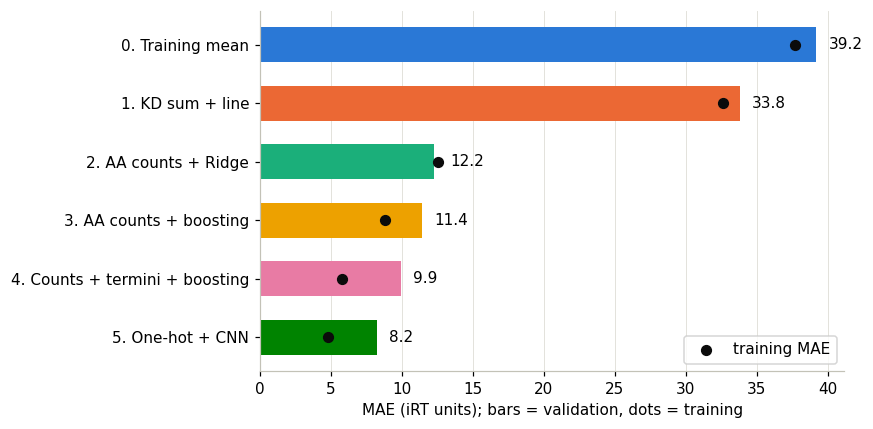

In [16]:
comparison = pd.DataFrame(results)
display(comparison)

colors = [approach_color(name) for name in comparison["Approach"]]
plt.figure(figsize=(8, 4))
plt.barh(comparison["Approach"], comparison["Val MAE"], color=colors, height=0.6)
plt.scatter(comparison["Train MAE"], comparison["Approach"], color="#0b0b0b", s=40, zorder=3,
            label="training MAE")
for y, (value, train_value) in enumerate(zip(comparison["Val MAE"], comparison["Train MAE"])):
    plt.annotate(f"{value:.1f}", (max(value, train_value), y), xytext=(8, 0), textcoords="offset points", va="center")
plt.gca().invert_yaxis()
plt.grid(axis="y", visible=False)
plt.xlabel("MAE (iRT units); bars = validation, dots = training")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

**What this cell does:** shows the results table and a bar chart of validation MAE (bars, value at the end) with training MAE as black dots.

**Peptides used:** training and validation peptides only. The test group is still untouched.

**Your check:** in the bar chart, a dot far to the left of its bar means the model fits training peptides much better than new peptides (overfitting). Name the approach with the largest gap and confirm it from the numbers in the table.

### 4.5 Predicted against recorded iRT, one panel per approach (validation)

All panels share the same axes, so they can be compared directly. Points on the black line are perfect predictions.

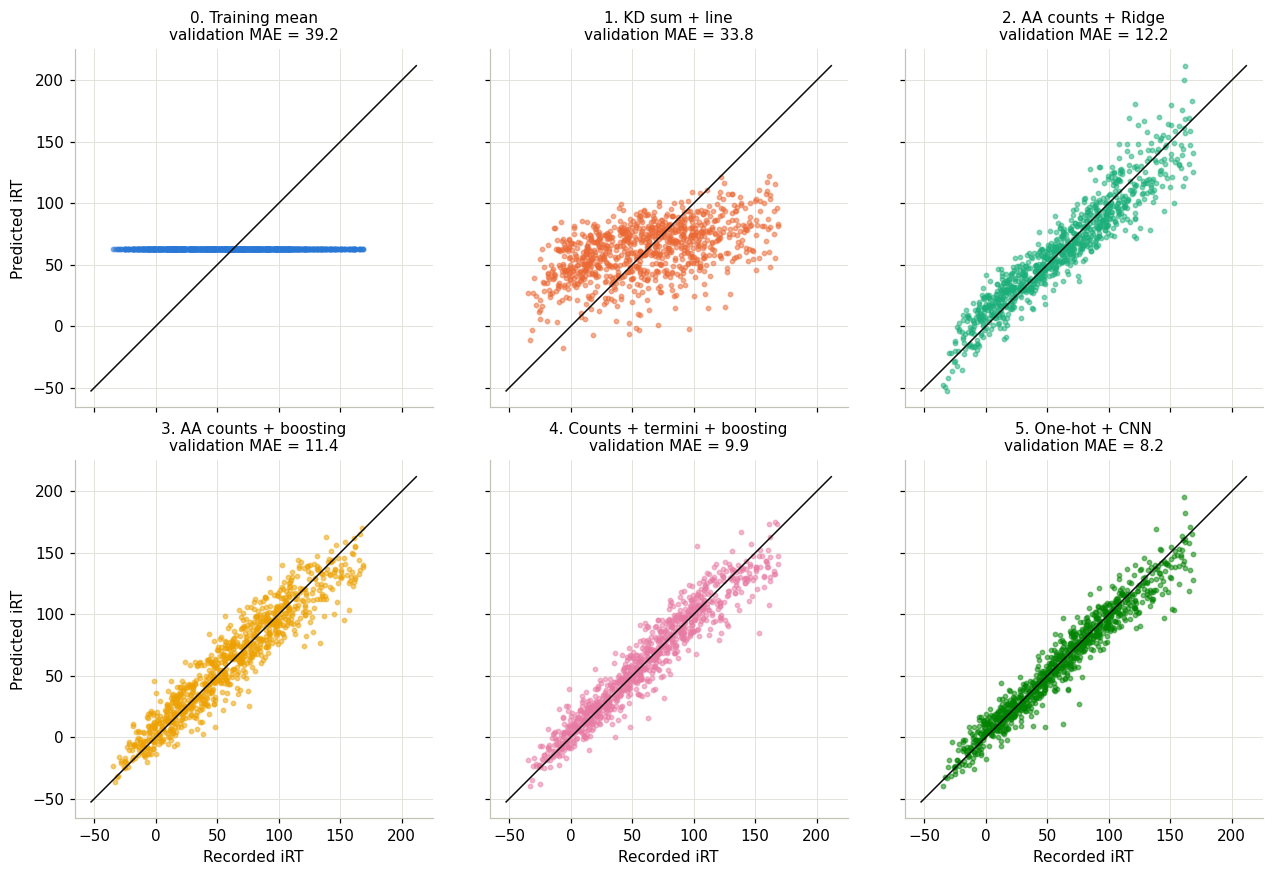

In [17]:
low = min(val["irt"].min(), min(p.min() for p in val_predictions.values()))
high = max(val["irt"].max(), max(p.max() for p in val_predictions.values()))

fig, axes = plt.subplots(2, 3, figsize=(12, 8), sharex=True, sharey=True)
for ax, (name, prediction) in zip(axes.ravel(), val_predictions.items()):
    ax.scatter(val["irt"], prediction, s=8, alpha=0.5, color=approach_color(name))
    ax.plot([low, high], [low, high], color="#0b0b0b", linewidth=1)
    val_mae = mean_absolute_error(val["irt"], prediction)
    ax.set_title(f"{name}\nvalidation MAE = {val_mae:.1f}", fontsize=10)
    ax.set_aspect("equal")
for ax in axes[1]:
    ax.set_xlabel("Recorded iRT")
for ax in axes[:, 0]:
    ax.set_ylabel("Predicted iRT")
plt.tight_layout()
plt.show()

**What this cell does:** draws predicted against recorded iRT for every approach, using the validation peptides. A flat cloud means the approach hardly uses the sequence (the training mean is a horizontal line); a narrow band along the diagonal means good predictions. Look also for curvature or for errors growing at the low or high end of the iRT range.

**Peptides used:** validation peptides; the models were trained on training peptides only.

**Your check:** the training-mean panel must be a perfectly horizontal row of points at the height printed in cell 3.9. Confirm this, and explain why its points lie exactly on one line.

### 4.6 Where are the errors? Peptide length and similarity to training (validation)

Left: validation MAE per length range. Right: validation MAE for peptides close to, typical for, or far from the training
peptides (bins from 3.7). The number of peptides in each range is shown under the x-axis: few peptides means a noisy value.

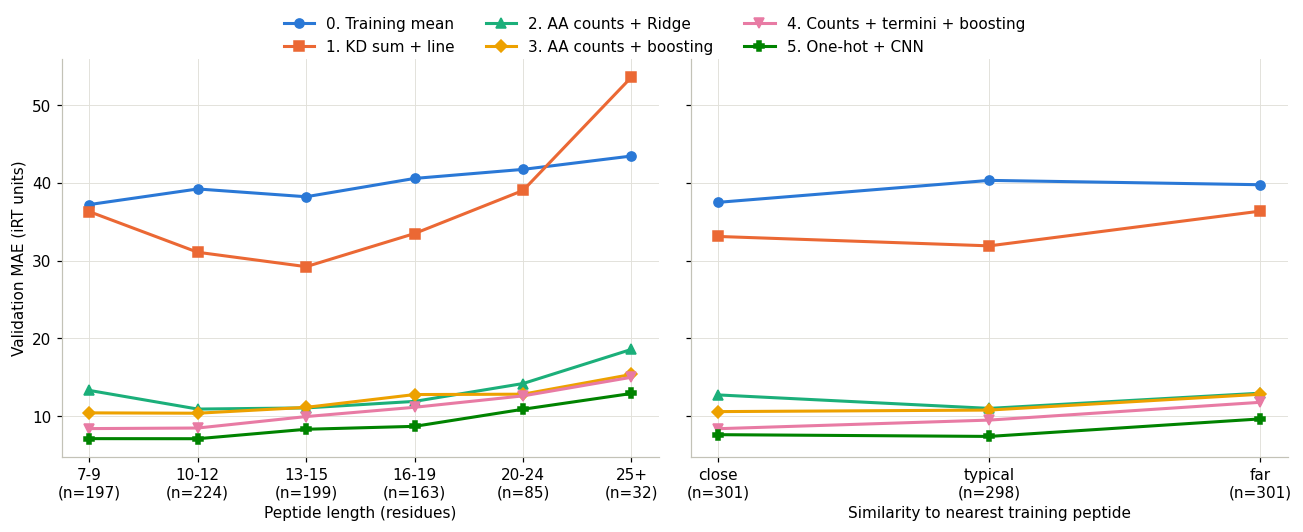

similarity,close,typical,far
0. Training mean,37.51,40.33,39.77
1. KD sum + line,33.12,31.91,36.38
2. AA counts + Ridge,12.74,11.01,12.97
3. AA counts + boosting,10.60,10.79,12.83
4. Counts + termini + boosting,8.40,9.50,11.79
5. One-hot + CNN,7.63,7.40,9.66


In [18]:
val_lengths = val["sequence"].str.len()
length_bins = pd.cut(val_lengths, [6, 9, 12, 15, 19, 24, 41], labels=["7-9", "10-12", "13-15", "16-19", "20-24", "25+"])
markers = ["o", "s", "^", "D", "v", "P"]

fig, (ax_len, ax_sim) = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
for (name, prediction), marker in zip(val_predictions.items(), markers):
    errors = pd.Series(np.abs(val["irt"] - prediction))
    by_length = errors.groupby(length_bins, observed=False).mean()
    by_similarity = errors.groupby(val["similarity"], observed=False).mean()
    ax_len.plot(range(len(by_length)), by_length.values, marker=marker, color=approach_color(name), label=name)
    ax_sim.plot(range(len(by_similarity)), by_similarity.values, marker=marker, color=approach_color(name))

length_counts = length_bins.value_counts().reindex(length_bins.cat.categories)
ax_len.set_xticks(range(len(length_counts)), [f"{b}\n(n={n})" for b, n in length_counts.items()])
ax_len.set_xlabel("Peptide length (residues)")
ax_len.set_ylabel("Validation MAE (iRT units)")
similarity_counts = val["similarity"].value_counts().reindex(["close", "typical", "far"])
ax_sim.set_xticks(range(3), [f"{b}\n(n={n})" for b, n in similarity_counts.items()])
ax_sim.set_xlabel("Similarity to nearest training peptide")
fig.legend(loc="upper center", ncol=3, bbox_to_anchor=(0.5, 1.08), frameon=False)
plt.tight_layout()
plt.show()

val_errors_by_bin = pd.DataFrame({
    name: pd.Series(np.abs(val["irt"] - prediction)).groupby(val["similarity"], observed=False).mean()
    for name, prediction in val_predictions.items()
}).T.round(2)
display(val_errors_by_bin)

**What this cell does:** splits the validation errors of every approach by peptide length (left) and by similarity to training (right), and prints the similarity numbers as a table. Lines that rise to the right mean long, or poorly represented, peptides are harder for that approach.

**Peptides used:** validation peptides; bins for similarity come from training distances (3.7).

**Your check:** pick one approach and one similarity bin in the table, then compute it yourself, for example `np.abs(val["irt"] - val_predictions["2. AA counts + Ridge"])[val["similarity"] == "far"].mean()`, and compare with the table and the plotted point.

Your comparison and final choice:

Complete the table above and explain your decision here. Then type the exact approach name in the first cell of section 5.

## 5. Assess your final choice

Now ask the LLM for code to evaluate the fixed choice on the test peptides.
Keep these results separate from the validation comparison. Include a plot of predicted
against recorded test iRT and inspect a few of the largest errors.

Check the reported numbers against the table and plot. Does the average error hide some
large mistakes? The error is in iRT units, not minutes.

Do not tune the model in response to the test results and then present the same test
as an independent final check. Further improvements need untouched evaluation data.
Optionally predict iRT for a peptide of your own: without its measured target,
you cannot know how accurate that prediction is.

### 5.1 Fix your choice, then evaluate once on the test group

Type the approach name exactly as in the comparison table. The cell stops with a message until you do, so the test group
cannot be used by accident. After running sections 5.1–5.3, make no further changes.

In [23]:
CHOSEN = (
    "5. One-hot + CNN"  # <- type your choice here, for example "2. AA counts + Ridge"
)

if CHOSEN not in predictors:
    raise ValueError("Set CHOSEN to one of: " + ", ".join(predictors))

test["predicted"] = predictors[CHOSEN](test["sequence"])
test["abs_error"] = np.abs(test["irt"] - test["predicted"])

test_scores = evaluate(test["irt"], test["predicted"])
print("Chosen approach:", CHOSEN)
print("Test peptides:", len(test))
for key, value in test_scores.items():
    print(f"Test {key}: {value:.2f}")
print(
    "\nFor comparison, validation:",
    comparison.set_index("Approach")
    .loc[CHOSEN, ["Val MAE", "Val R2", "Val Delta95"]]
    .to_dict(),
)

Chosen approach: 5. One-hot + CNN
Test peptides: 900
Test MAE: 8.24
Test R2: 0.94
Test Delta95: 43.60

For comparison, validation: {'Val MAE': 8.23, 'Val R2': 0.94, 'Val Delta95': 42.69}


**What this cell does:** predicts the test peptides with the fixed model (trained on training peptides only, settings chosen on validation) and reports test MAE, R² and Δ95 next to the validation values.

**Peptides used:** test peptides, for the first and only time.

**Your check:** `test["abs_error"].mean()` must equal the printed test MAE. Also count by hand: is the number of test peptides the same as in cell 3.5?

### 5.2 Predicted against recorded iRT (test group)

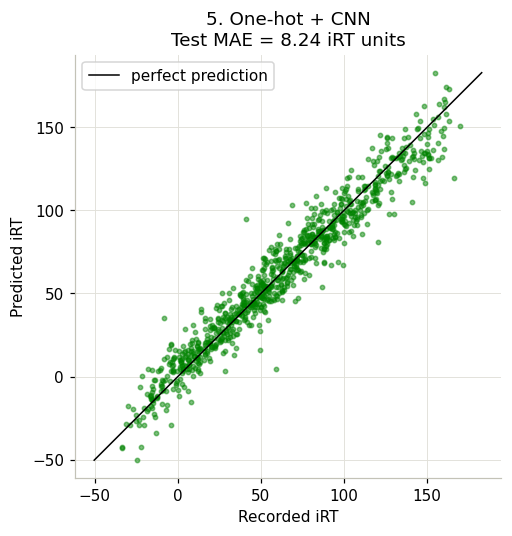

In [24]:
low, high = test[["irt", "predicted"]].min().min(), test[["irt", "predicted"]].max().max()
plt.figure(figsize=(5, 5))
plt.scatter(test["irt"], test["predicted"], s=8, alpha=0.5, color=approach_color(CHOSEN))
plt.plot([low, high], [low, high], color="black", linewidth=1, label="perfect prediction")
plt.xlabel("Recorded iRT")
plt.ylabel("Predicted iRT")
plt.title(f"{CHOSEN}\nTest MAE = {test_scores['MAE']:.2f} iRT units")
plt.legend()
plt.axis("equal")
plt.show()

**What this cell does:** plots each test peptide's predicted iRT against its recorded iRT. Points on the black line are perfect predictions.

**Peptides used:** test peptides.

**Your check:** pick one point far from the line in the plot, find it in the table of 5.3 by its recorded iRT, and confirm that its vertical distance to the line matches its `abs_error`.

### 5.3 The largest test errors

Look for patterns: are they long or short, far from training peptides, rich in rare residues, or at the ends of the iRT range?

,sequence,length,irt,predicted,abs_error,nearest_train_dist,similarity
445,LESHLYR,7,58.78,4.270000,54.52,0.43,close
788,VASDMMVLLK,10,40.95,94.709999,53.75,0.40,close
533,LVQNIIQTAVDQFVR,15,166.27,119.209999,47.06,0.53,typical
795,VERCMSVMQSGTQMIK,16,-8.02,35.040001,43.07,0.56,far
174,ELENIIQETEKELDPDGLKK,20,120.45,80.949997,39.50,0.50,typical
549,MELSQLLNEIR,11,140.76,105.169998,35.59,0.45,close
235,FSHLTSLPQQLPSQQLMSK,19,68.65,103.330002,34.68,0.58,far
475,LLEEADK,7,49.75,16.059999,33.69,0.29,close
341,IGPPSPGDDEEEAAAAAGAPAAAGATGDLASAQLGGAPNR,40,86.64,53.959999,32.68,0.62,far
260,GDTDIMSDLFGLHPK,15,130.24,97.820000,32.41,0.53,typical


Test MAE per similarity bin:
            mean  count
similarity             
close       8.14    290
typical     7.80    308
far         8.78    302

Share of test peptides with an error above the test MAE: 0.4
Largest error: 54.52  vs. test MAE: 8.24


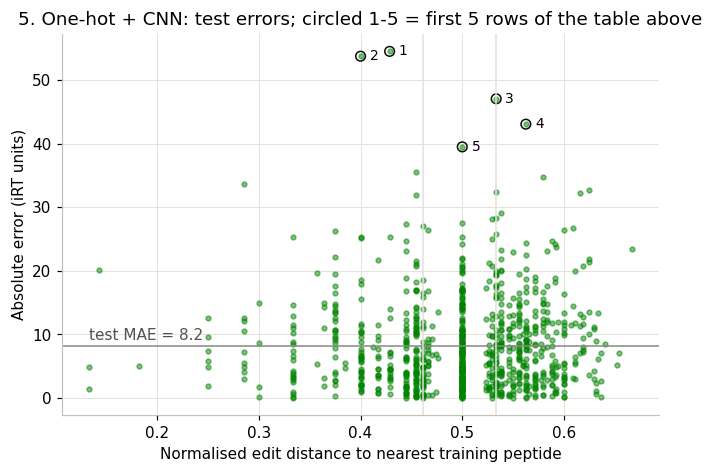

In [25]:
test["length"] = test["sequence"].str.len()
columns = ["sequence", "length", "irt", "predicted", "abs_error", "nearest_train_dist", "similarity"]
display(test.nlargest(15, "abs_error")[columns].round(2))

print("Test MAE per similarity bin:")
print(test.groupby("similarity", observed=False)["abs_error"].agg(["mean", "count"]).round(2))
print("\nShare of test peptides with an error above the test MAE:", round((test["abs_error"] > test_scores["MAE"]).mean(), 2))
print("Largest error:", round(test["abs_error"].max(), 2), " vs. test MAE:", round(test_scores["MAE"], 2))

# Are the worst peptides the ones unlike anything in training?
plt.figure(figsize=(7, 4.5))
plt.scatter(test["nearest_train_dist"], test["abs_error"], s=10, alpha=0.5, color=approach_color(CHOSEN))
plt.axhline(test_scores["MAE"], color="#898781", linewidth=1)
plt.annotate(f"test MAE = {test_scores['MAE']:.1f}", (test["nearest_train_dist"].min(), test_scores["MAE"]),
             xytext=(0, 4), textcoords="offset points", color="#52514e")
largest = test.nlargest(5, "abs_error")
plt.scatter(largest["nearest_train_dist"], largest["abs_error"], s=40, facecolor="none", edgecolor="#0b0b0b")
for rank, (_, row) in enumerate(largest.iterrows(), start=1):
    plt.annotate(str(rank), (row["nearest_train_dist"], row["abs_error"]),
                 xytext=(6, 0), textcoords="offset points", va="center", fontsize=9)
for edge in bin_edges[1:3]:
    plt.axvline(edge, color="#e1e0d9", linewidth=1)
plt.xlabel("Normalised edit distance to nearest training peptide")
plt.ylabel("Absolute error (iRT units)")
plt.title(f"{CHOSEN}: test errors; circled 1-5 = first 5 rows of the table above")
plt.show()

**What this cell does:** lists the 15 test peptides with the largest errors with their length and similarity to training, shows test MAE for close / typical / far peptides, and plots each test peptide's error against its distance to the nearest training peptide (light vertical lines: bin edges). If the labelled worst peptides sit on the right, errors come mostly from unusual peptides; if they are spread out, other causes (length, rare residues, iRT range) are more likely.

**Peptides used:** test peptides (training sequences only through the distances computed in 3.7).

**Your check:** take the first sequence in the table and work out its absolute error by hand from the `irt` and `predicted` columns.

## 6. Explain your work

Answer in your own words, using your results as evidence:

1. What are the samples, input and target? Why is iRT different from minutes?
2. Which features and model did you choose, and why? What information does your representation lose?
3. How did you keep training, validation and test data separate? Show one concrete check
   you made on the code or its output rather than relying on the LLM's explanation.
4. What changed in your revised approach? Use the validation results to justify your final
   choice, then report its test error. Did the results support the LLM's expectations?
5. What can you conclude for this dataset, and what remains untested for another peptide
   population, modification or LC method? Identify one LLM suggestion you corrected or checked.

Your answers:

1.

2.

3.

4.

5.

## 7. Keep your prompts and checks

Save the exact prompts that led to important decisions or corrections. Your code stays in
this notebook; you do not need to paste the entire chat here.

| Exact prompt and assistant used | What you accepted or changed | How you checked it |
|---|---|---|
| Claude (Opus 5.5, Claude Code): planning prompt asking for 5 approaches, data checks, a 70/15/15 split with recorded seed, training-only learning, choice on validation, one test evaluation, and an edit-distance analysis of how well peptides are represented in training | Accepted 5 approaches (KD sum + line, counts + Ridge, counts + boosting, counts + termini + boosting, one-hot + CNN) | |
| Claude: "1. Use the MAE, R2 and delta 95 2. Ok, remove duplicates 3. I would like to force related peptides into the same group 4. Lets do 70/15/15 5. Lets do Kyte-Doolittle 6. Lets do Keras 7. Should be the standard 20" | Changed: related peptides (one inside another) forced into one group instead of only reported | |

If LLM access is unavailable, ask the instructor for help or an example response and say
what you used. Do not invent a chat interaction. No paid subscription or API key is required
by this notebook.

Your finished notebook should contain your plan, working code, validation comparison,
final test results and plot, answers to the five questions, and a short prompt log.

## Data and reuse

The [DLOmix example CSV](https://raw.githubusercontent.com/wilhelm-lab/dlomix/f67623048c8692823cff88c3a7521123697af781/example_dataset/proteomTools_train_val.csv) contains 34,000 peptide sequences with experimentally
derived iRT targets. We use a fixed random subset of 6,000. The
[ProteomicsML description](https://proteomicsml.org/datasets/retentiontime/DLOmix_RT.html)
connects these data to [ProteomeTools](https://doi.org/10.1038/nmeth.4153), PXD004732.
Credit the experimental authors and the DLOmix contributors. The source is distributed
in the [MIT-licensed DLOmix repository](https://github.com/wilhelm-lab/dlomix/blob/f67623048c8692823cff88c3a7521123697af781/LICENSE).

The two-column file lacks modification annotations, run and batch identifiers, and detailed
LC conditions. Plain sequence strings do not specify every chemical modification.
A sequence-disjoint split can still contain related peptides and does not validate transfer
to another laboratory. Converting iRT to experimental time requires local calibration.
See the [dataset provenance and backup](https://github.com/CompOmics/ML_AI_Analytical_Chemistry_Course/tree/main/datasets/peptide_rt).
This practical is not a reproduction of a published benchmark.